# ECSE 551 – Assignment 1
## Task 1: Data loading, preprocessing and statistical analysis

In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.datasets import load_diabetes, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "figure.dpi": 100})
sns.set_style("whitegrid")
pd.set_option("display.precision", 3)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


### 1(a) Load the datasets

In [112]:
diabetes = load_diabetes()
df_diab = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df_diab["target"] = diabetes.target
print(f"Features: {list(diabetes.feature_names)}")

digits = load_digits()
df_digits = pd.DataFrame(digits.data, columns=[f"px{i}" for i in range(64)])
df_digits["target"] = digits.target

print("Diabetes shape:", df_diab.shape, "| Digits shape:", df_digits.shape)

# aliases used by Task 2(b) classification below
X_dig, y_dig = digits.data, digits.target


Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Diabetes shape: (442, 11) | Digits shape: (1797, 65)


### 1(b) Check for missing, erroneous and outlying values

In [113]:
for name, df in [("Diabetes", df_diab), ("Digits", df_digits)]:
    print(f"{name}: missing values = {df.isna().sum().sum()}, duplicate rows = {df.duplicated().sum()}")

pixels = df_digits.drop(columns="target")
print("Diabetes target range:", df_diab["target"].min(), "to", df_diab["target"].max())
print("Digits pixel range:", pixels.values.min(), "to", pixels.values.max(),
      "| all integers:", bool(np.all(pixels.values % 1 == 0)))
print("Digits constant pixels:", list(pixels.columns[pixels.std() == 0]))
print("Digits images per class:", df_digits["target"].value_counts().sort_index().tolist())

Diabetes: missing values = 0, duplicate rows = 0
Digits: missing values = 0, duplicate rows = 0
Diabetes target range: 25.0 to 346.0
Digits pixel range: 0.0 to 16.0 | all integers: True
Digits constant pixels: ['px0', 'px32', 'px39']
Digits images per class: [178, 182, 177, 183, 181, 182, 181, 179, 174, 180]


In [114]:
features = df_diab.drop(columns="target")
q1, q3 = features.quantile(0.25), features.quantile(0.75)
iqr = q3 - q1
is_outlier = (features < q1 - 1.5 * iqr) | (features > q3 + 1.5 * iqr)
print("IQR outliers per feature:", is_outlier.sum().to_dict())
print("Rows with at least one outlier:", is_outlier.any(axis=1).sum(), "of", len(features))

IQR outliers per feature: {'age': 0, 'sex': 0, 'bmi': 3, 'bp': 0, 's1': 8, 's2': 7, 's3': 7, 's4': 2, 's5': 4, 's6': 9}
Rows with at least one outlier: 31 of 442


Neither dataset has missing or duplicated values, and all values are within valid ranges (pixels are integers from
0 to 16, target is positive). The IQR rule flags 31 of 442 diabetes patients, but these likely result from the skewed features rather than from errors. Removing 7% of a small dataset would cost too much. The digit dataset has three pixels that are always 0 i.e., they carry no information. The ten classes are near evenly distributed (174 to 183 images each).

### 1(c) Statistical analysis: Diabetes

In [115]:
df_diab.agg(["mean", "std", "min", "max", "nunique", "skew", "kurt"]).T.round(3)

,mean,std,min,max,nunique,skew,kurt
age,-0.000,0.048,-0.107,0.111,58.0,-0.231,-0.671
sex,0.000,0.048,-0.045,0.051,2.0,0.127,-1.993
bmi,-0.000,0.048,-0.090,0.171,163.0,0.598,0.095
bp,-0.000,0.048,-0.112,0.132,100.0,0.291,-0.533
s1,-0.000,0.048,-0.127,0.154,141.0,0.378,0.233
s2,0.000,0.048,-0.116,0.199,302.0,0.437,0.601
s3,-0.000,0.048,-0.102,0.181,63.0,0.799,0.982
s4,-0.000,0.048,-0.076,0.185,66.0,0.735,0.444
s5,0.000,0.048,-0.126,0.134,184.0,0.292,-0.134
s6,0.000,0.048,-0.138,0.136,56.0,0.208,0.237


The features all have mean 0 and the same standard deviation (0.048) because load_diabetes() returns them
already centred and scaled; only the target is in its original units. In raw units, the features
have very different ranges (e.g., age 19 to 79 versus cholesterol 97 to 301), so scaling is needed for the L1/L2 penalties of Lasso and ElasticNet to treat all features equally. The provided data already satisfy this.

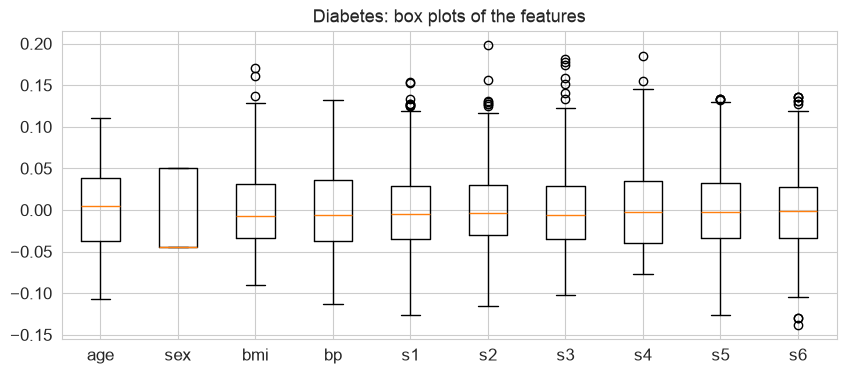

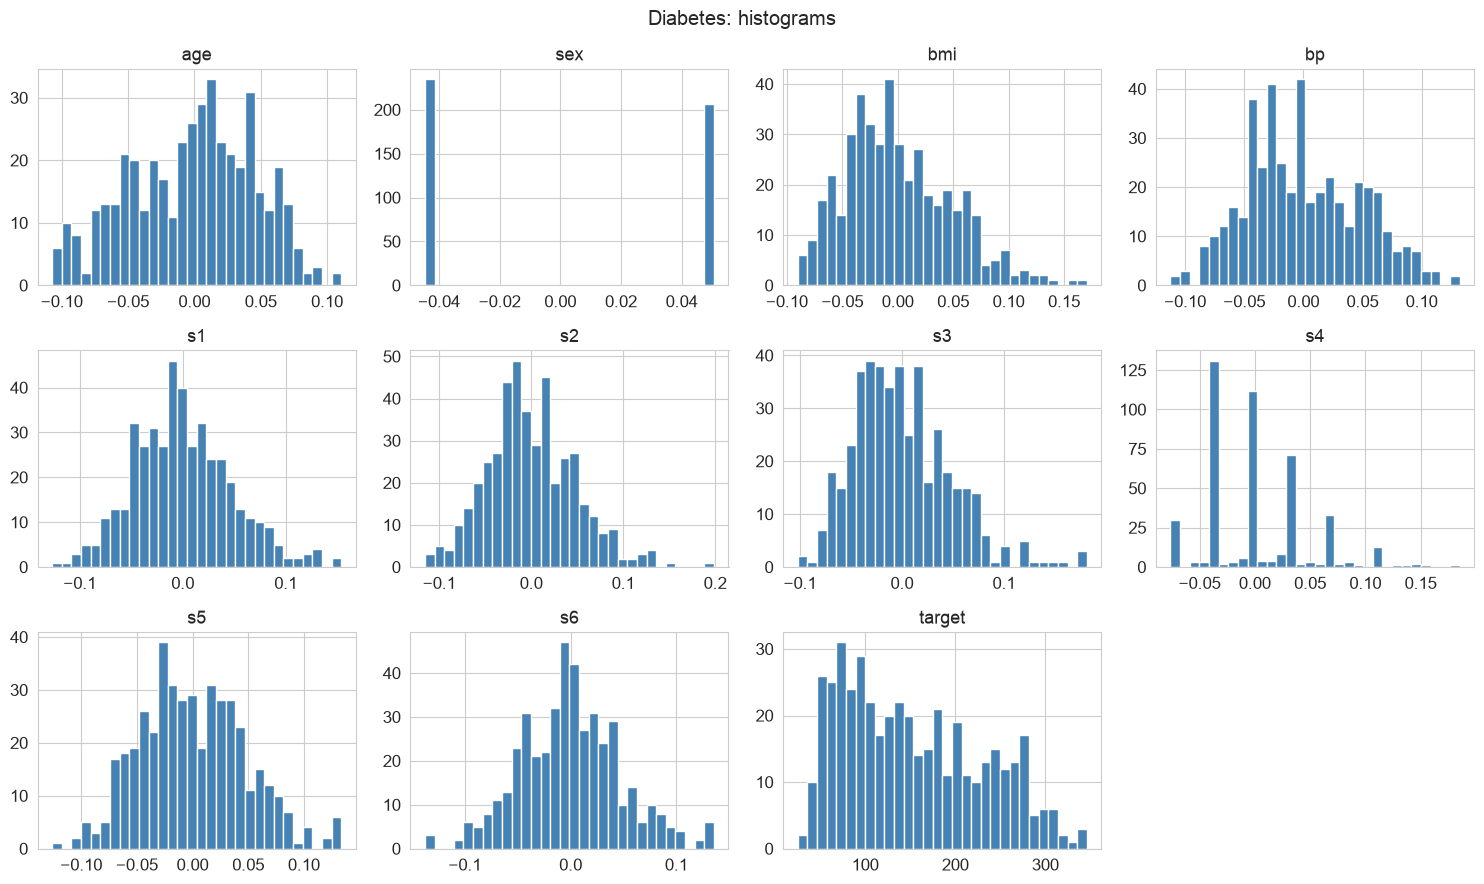

In [116]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(features.values)
ax.set_xticks(range(1, features.shape[1] + 1), features.columns)
ax.set_title("Diabetes: box plots of the features")
fig.savefig(FIG_DIR / "diabetes_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.ravel(), df_diab.columns):
    ax.hist(df_diab[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
fig.suptitle("Diabetes: histograms")
fig.tight_layout()
fig.savefig(FIG_DIR / "diabetes_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

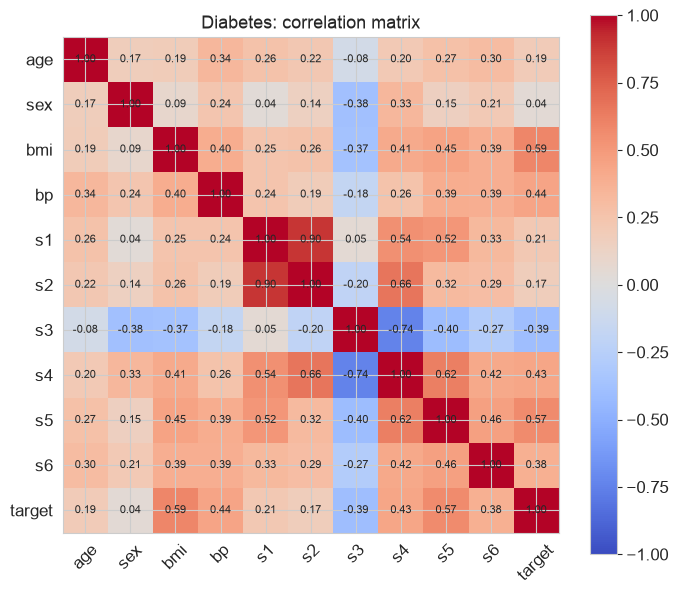

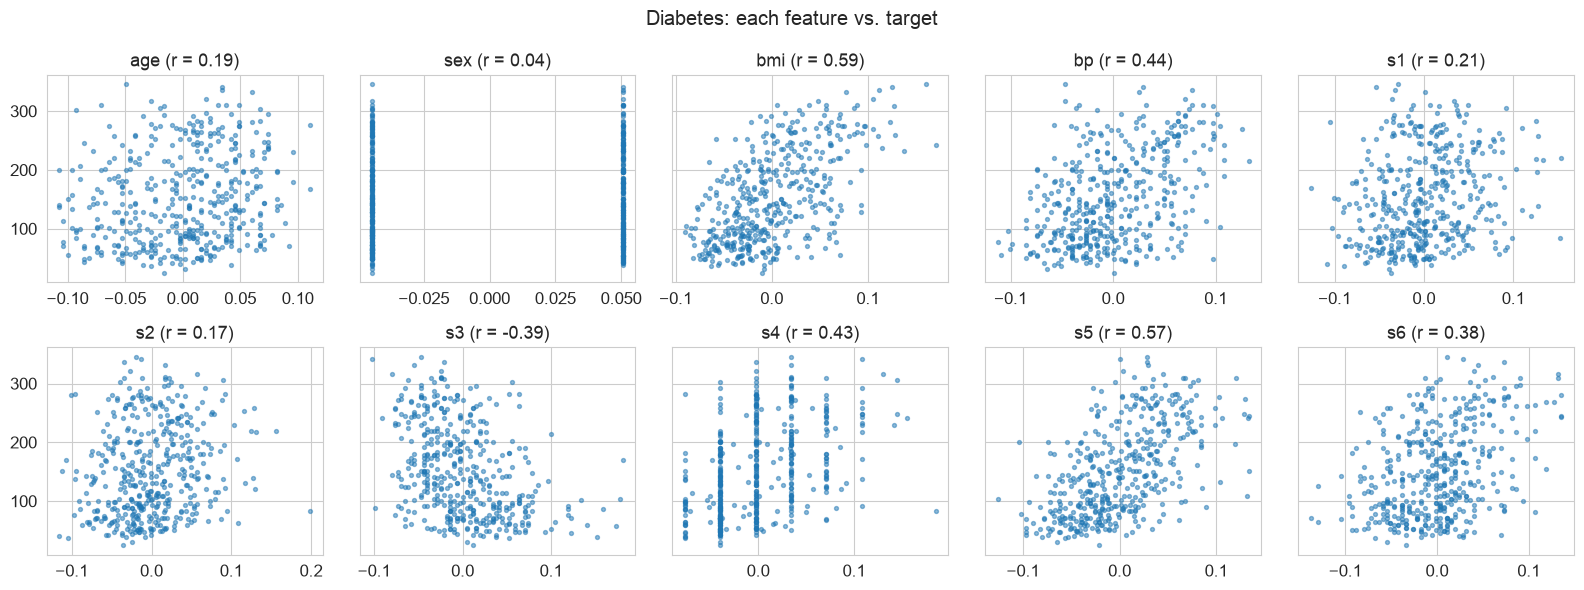

In [117]:
corr = df_diab.corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Diabetes: correlation matrix")
fig.savefig(FIG_DIR / "diabetes_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=True)
for ax, col in zip(axes.ravel(), features.columns):
    ax.scatter(df_diab[col], df_diab["target"], s=8, alpha=0.5)
    ax.set_title(f"{col} (r = {corr.loc[col, 'target']:.2f})")
fig.suptitle("Diabetes: each feature vs. target")
fig.tight_layout()
fig.savefig(FIG_DIR / "diabetes_feature_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings:** `sex` is a binary feature, and `s4` is almost discrete. Most of '`s4`'s values are rounded. All other variables are continuous and unimodal. `s3`, `s4` and `bmi` are right-skewed (skew 0.6 to 0.8), and the target is also right-skewed. None of the variables are heavy-tailed (Kurtosis < 3), so the distributions are close to Gaussian or have light tails. The features most correlated with the target are `bmi` (0.59) and `s5` (0.57). Some features are strongly correlated with each other: `s1` and
`s2` (0.90) and `s3` and `s4` (−0.74). This is relevant since Lasso tends to keep only one feature from
a correlated group while ElasticNet tends to share the weight between them.

### 1(c) Statistical analysis: Digits

Pixel means range from 0.00 to 12.09; pixel standard deviations range from 0.00 to 6.54


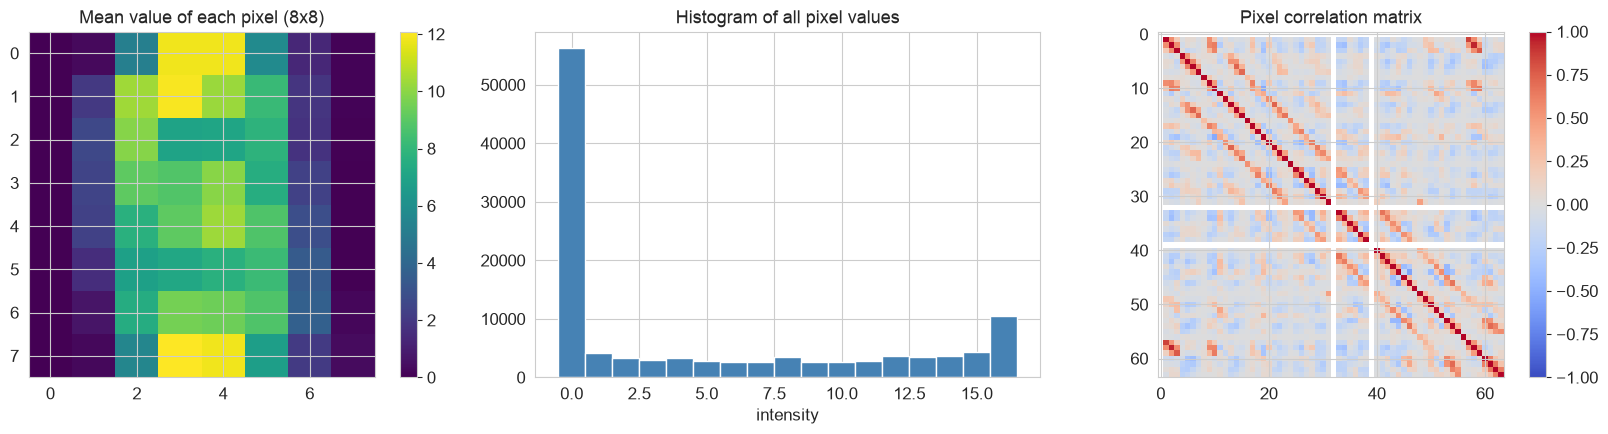

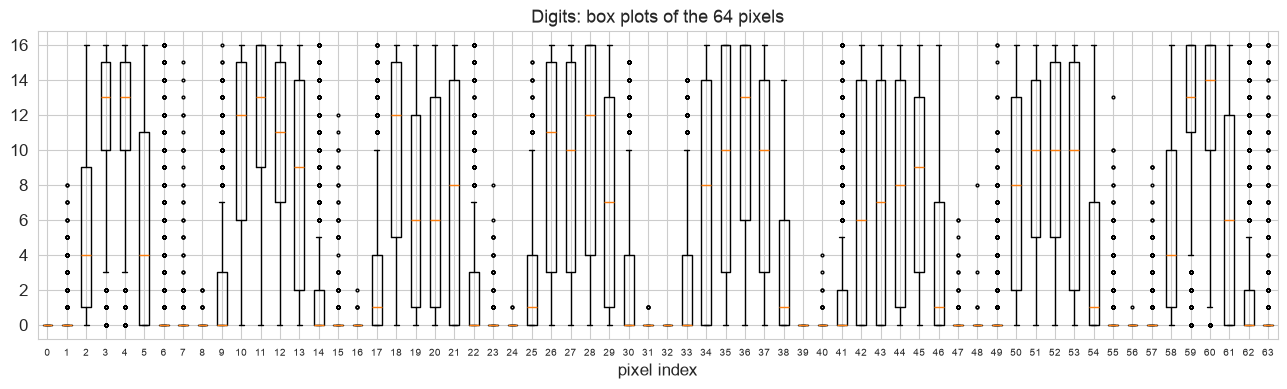

In [118]:
print(f"Pixel means range from {pixels.mean().min():.2f} to {pixels.mean().max():.2f}; "
      f"pixel standard deviations range from {pixels.std().min():.2f} to {pixels.std().max():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
im = axes[0].imshow(pixels.mean().values.reshape(8, 8), cmap="viridis")
fig.colorbar(im, ax=axes[0])
axes[0].set_title("Mean value of each pixel (8x8)")

axes[1].hist(pixels.values.ravel(), bins=np.arange(18) - 0.5, color="steelblue", edgecolor="white")
axes[1].set_title("Histogram of all pixel values")
axes[1].set_xlabel("intensity")

im = axes[2].imshow(pixels.corr(), cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[2])
axes[2].set_title("Pixel correlation matrix")
fig.tight_layout()
fig.savefig(FIG_DIR / "digits_summary.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(16, 4))
ax.boxplot(pixels.values, flierprops={"markersize": 2})
ax.set_xticks(range(1, 65), range(64))
ax.tick_params(axis="x", labelsize=7)
ax.set_xlabel("pixel index")
ax.set_title("Digits: box plots of the 64 pixels")
fig.savefig(FIG_DIR / "digits_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings:** All pixels share the same 0 to 16 integer scale, but their means and spreads differ a lot: border
pixels are almost always 0, while central pixels vary over the full range. The pixel values are strongly bimodal,
with about half of them equal to 0 (background) and a second peak at 16 (fully inked). Neighbouring pixels are
positively correlated, which shows up as red bands next to the diagonal of the correlation matrix.


## Task 2: Models from scratch vs scikit-learn
70/30 split (`random_state=42`). Hyperparameters are chosen by 5-fold CV on the training set.

In [119]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix

RANDOM_STATE = 42
# same folds for every model so CV scores are comparable
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### 2(a) Regression: Diabetes

In [120]:
def soft_threshold(z, t):
    return np.sign(z) * np.maximum(np.abs(z) - t, 0)


class ElasticNetRegression:
    """
    Linear regression with combined L1 and L2 regularization and soft thresholding.

    Objective minimized:
        J(W, b) = (1 / 2m) * ||Y - (XW + b)||^2
                  + penalty * ( l1_ratio * ||W||_1
                              + (1 - l1_ratio) / 2 * ||W||_2^2 )

    l1_ratio = 1.0 -> pure Lasso, l1_ratio = 0.0 -> pure Ridge.
    The bias b is not regularized.
    """

    def __init__(self, learning_rate, iterations, penalty, l1_ratio=0.5):
        self.loss_history = None
        self.b = None
        self.W = None
        self.n = None
        self.m = None
        self.Y = None
        self.X = None
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.penalty = penalty
        self.l1_ratio = l1_ratio

    def fit(self, X, Y):
        # training loop
        self.X = np.asarray(X, dtype=float)
        self.Y = np.asarray(Y, dtype=float).ravel()
        self.m, self.n = self.X.shape

        self.W = np.zeros(self.n)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.iterations):
            self.update_weights()
        return self

    def update_weights(self):
        Y_pred = self.predict(self.X)
        error = self.Y - Y_pred

        mse = (error @ error) / (2 * self.m)
        reg = self.penalty * (
            self.l1_ratio * np.abs(self.W).sum()
            + 0.5 * (1 - self.l1_ratio) * (self.W @ self.W)
        )
        self.loss_history.append(mse + reg)

        dW = -(self.X.T @ error) / self.m + self.penalty * (1 - self.l1_ratio) * self.W
        db = -1 / self.m * error.sum()

        W_step = self.W - self.learning_rate * dW

        threshold = self.learning_rate * self.penalty * self.l1_ratio

        self.W = soft_threshold(W_step, threshold)
        self.b -= self.learning_rate * db

        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.W + self.b

**Note:** Lasso regression is functionally identical to ElasticNet regression with an L1 ratio of 1


In [121]:
test_size = 0.30
seed = 42

(X, y) = df_diab.drop(columns="target").values, df_diab["target"].values

rng = np.random.default_rng(seed)
shuffled_idx = rng.permutation(len(X))

split_idx = int((1 - test_size) * len(X))

train_idx = shuffled_idx[:split_idx]
test_idx = shuffled_idx[split_idx:]

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

Train: 309 rows | Test: 133 rows


#### Learning rate / iteration sensitivity

lr = 1.00e-03, final loss = 7237.56 (ok)
lr = 1.00e-02, final loss = 2850.76 (ok)
lr = 1.00e-01, final loss = 2450.26 (ok)
lr = 1.00e+00, final loss = 2226.21 (ok)
lr = 1.50e+00, final loss = 2226.09 (ok)
lr = 2.00e+00, final loss = 14257.50 (ok)
best lr: 1.50e+00


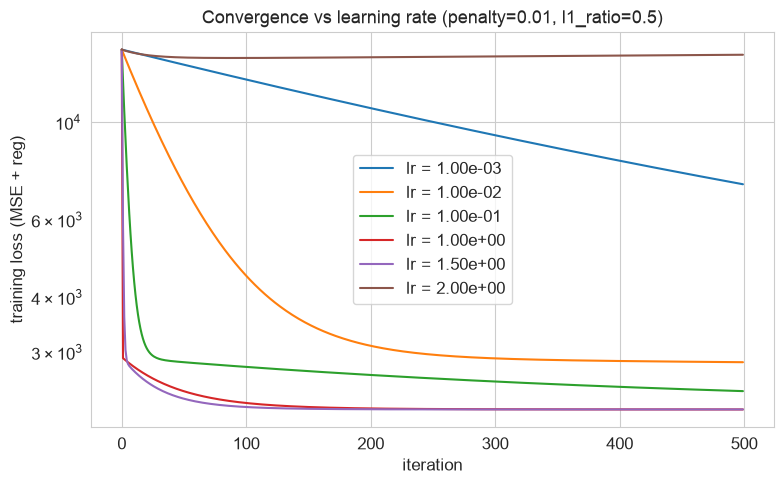

In [122]:
penalty = 0.01
l1_ratio = 0.5
iterations = 500
lr_best, loss_best = None, np.inf

fig, ax = plt.subplots(figsize=(8, 5))
for lr in [1e-3, 1e-2, 1e-1, 1.0, 1.5, 2.0]:
    model = ElasticNetRegression(lr, iterations, penalty, l1_ratio)
    model.fit(X_train, y_train)
    ax.semilogy(model.loss_history, label=f"lr = {lr:.2e}")
    final = model.loss_history[-1]
    status = "ok" if np.isfinite(final) else "diverged"
    print(f"lr = {lr:.2e}, final loss = {final:.2f} ({status})")
    if np.isfinite(final) and final < loss_best:
        loss_best = final
        lr_best = lr

print("best lr:", f"{lr_best:.2e}")

ax.set_xlabel("iteration")
ax.set_ylabel("training loss (MSE + reg)")
ax.set_title(f"Convergence vs learning rate (penalty={penalty}, l1_ratio={l1_ratio})")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "lr_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

#### Regularization-path sweep

In [123]:
def mse(y_true, y_pred):
    err = y_true - y_pred
    return (err @ err) / len(err)


lambdas = np.logspace(-4, 1, 35)
l1_ratios = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
iterations = 10000

# Largest eigenvalue of X^T X / m. The W-stability bound is 2 / (L_X + lambda * (1 - r));
# the bias-stability bound is 2 (its Hessian is 1). We use lr = 1.5 / max(1, L_X + ...)
# so a single step size stays inside both bounds for every (lambda, r) in the sweep.
L_X = np.linalg.eigvalsh(X_train.T @ X_train / len(X_train))[-1]

n_r, n_l = len(l1_ratios), len(lambdas)
W_path = np.zeros((n_r, n_l, X_train.shape[1]))
train_mse = np.zeros((n_r, n_l))
test_mse = np.zeros((n_r, n_l))

for i, r in enumerate(l1_ratios):
    for j, lam in enumerate(lambdas):
        lr = 1.5 / max(1.0, L_X + lam * (1 - r))
        model = ElasticNetRegression(lr, iterations, lam, r)
        model.fit(X_train, y_train)
        W_path[i, j] = model.W
        train_mse[i, j] = mse(y_train, model.predict(X_train))
        test_mse[i, j] = mse(y_test, model.predict(X_test))

best_i, best_j = np.unravel_index(np.argmin(test_mse), test_mse.shape)
print(f"best test MSE = {test_mse[best_i, best_j]:.2f} "
      f"at l1_ratio = {l1_ratios[best_i]:.2f}, lambda = {lambdas[best_j]:.2e}")

best test MSE = 2556.71 at l1_ratio = 1.00, lambda = 2.25e-02


In [124]:
from sklearn.linear_model import LinearRegression, Lasso

r1 = int(np.where(l1_ratios == 1.0)[0][0])

ols = LinearRegression().fit(X_train, y_train)
print(f"OLS test MSE                   : {mse(y_test, ols.predict(X_test)):.2f}")
print(f"ours @ smallest lambda (Lasso) : {test_mse[r1, 0]:.2f}")
print()
print(f"{'alpha':>8}  {'sklearn Lasso':>14}  {'nearest lambda':>14}  {'ours':>10}")
for a in [1e-3, 1e-2, 1e-1, 1.0]:
    sk = Lasso(alpha=a, max_iter=50000).fit(X_train, y_train)
    j = int(np.argmin(np.abs(lambdas - a)))
    print(f"{a:>8.3g}  {mse(y_test, sk.predict(X_test)):>14.2f}  "
          f"{lambdas[j]:>14.3g}  {test_mse[r1, j]:>10.2f}")

OLS test MSE                   : 2538.68
ours @ smallest lambda (Lasso) : 2559.08

   alpha   sklearn Lasso  nearest lambda        ours
   0.001         2539.36         0.00107     2558.87
    0.01         2559.59          0.0115     2557.16
     0.1         2597.46          0.0873     2585.98
       1         3702.67           0.935     3580.76


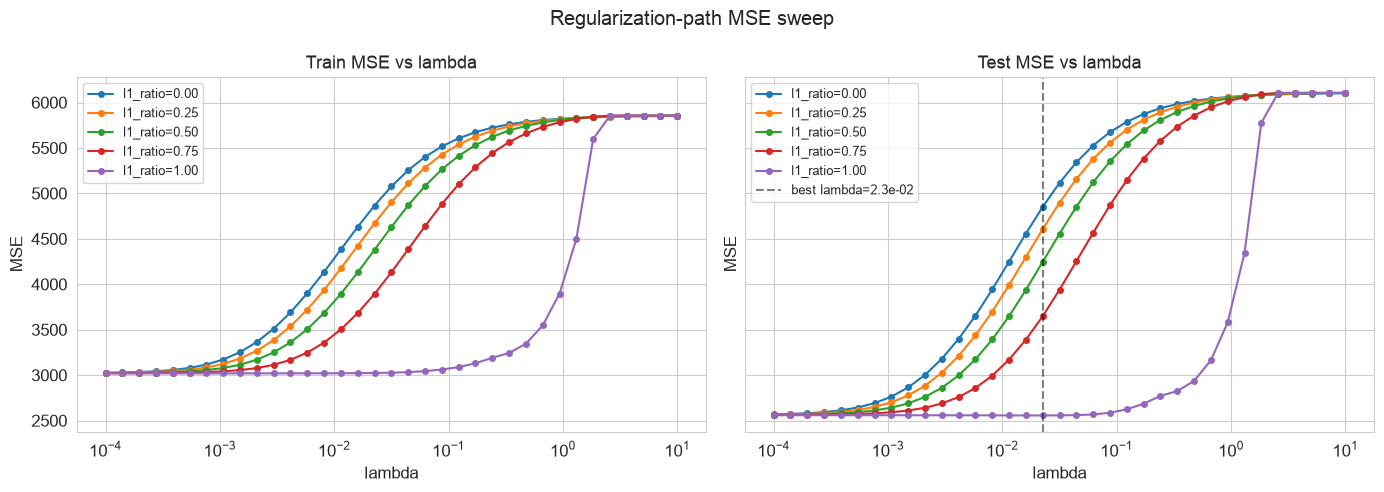

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for i, r in enumerate(l1_ratios):
    axes[0].semilogx(lambdas, train_mse[i], marker="o", ms=4, label=f"l1_ratio={r:.2f}")
    axes[1].semilogx(lambdas, test_mse[i], marker="o", ms=4, label=f"l1_ratio={r:.2f}")

axes[0].set_title("Train MSE vs lambda")
axes[1].set_title("Test MSE vs lambda")
axes[1].axvline(lambdas[best_j], color="k", linestyle="--", alpha=0.5,
                label=f"best lambda={lambdas[best_j]:.1e}")
for ax in axes:
    ax.set_xlabel("lambda")
    ax.set_ylabel("MSE")
    ax.legend(fontsize=9)
fig.suptitle("Regularization-path MSE sweep")
fig.tight_layout()
fig.savefig(FIG_DIR / "regpath_mse.png", dpi=150, bbox_inches="tight")
plt.show()

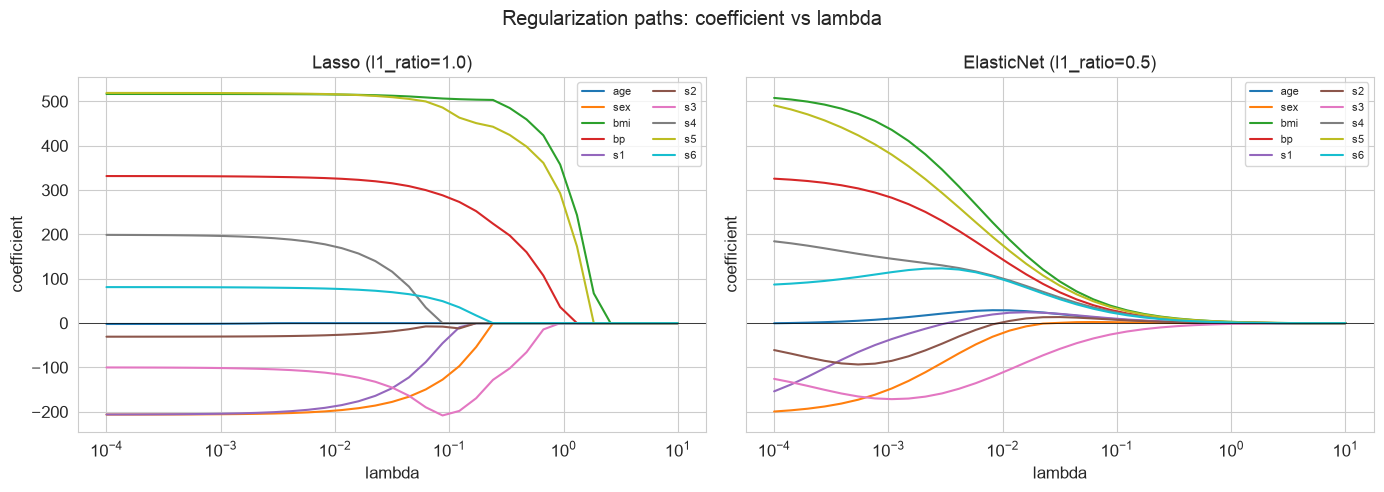

In [126]:
feature_names = df_diab.drop(columns="target").columns.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, r_idx, title in [
    (axes[0], np.where(l1_ratios == 1.0)[0][0], "Lasso (l1_ratio=1.0)"),
    (axes[1], np.where(l1_ratios == 0.5)[0][0], "ElasticNet (l1_ratio=0.5)"),
]:
    for k, name in enumerate(feature_names):
        ax.semilogx(lambdas, W_path[r_idx, :, k], label=name)
    ax.axhline(0, color="k", linewidth=0.5)
    ax.set_xlabel("lambda")
    ax.set_ylabel("coefficient")
    ax.set_title(title)
    ax.legend(fontsize=8, ncol=2)

fig.suptitle("Regularization paths: coefficient vs lambda")
fig.tight_layout()
fig.savefig(FIG_DIR / "regpath_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

#### 5-fold cross-validation

Picking the best `(lambda, l1_ratio)` on the test set would be peeking. We pick on 5-fold CV
inside the training set and only use the test set to report final MSE.

In [127]:
K = 5
rng_cv = np.random.default_rng(seed)
fold_order = rng_cv.permutation(len(X_train))
folds = np.array_split(fold_order, K)

cv_mse = np.zeros((n_r, n_l))

for i, r in enumerate(l1_ratios):
    for j, lam in enumerate(lambdas):
        lr = 1.5 / max(1.0, L_X + lam * (1 - r))
        fold_errs = np.empty(K)
        for k in range(K):
            val_idx = folds[k]
            tr_idx = np.concatenate([folds[kk] for kk in range(K) if kk != k])
            m_cv = ElasticNetRegression(lr, iterations, lam, r).fit(X_train[tr_idx], y_train[tr_idx])
            fold_errs[k] = mse(y_train[val_idx], m_cv.predict(X_train[val_idx]))
        cv_mse[i, j] = fold_errs.mean()

cv_i, cv_j = np.unravel_index(np.argmin(cv_mse), cv_mse.shape)
r1 = int(np.where(l1_ratios == 1.0)[0][0])
cv_j_lasso = int(np.argmin(cv_mse[r1]))

print(f"CV-best overall : l1_ratio={l1_ratios[cv_i]:.2f}, "
      f"lambda={lambdas[cv_j]:.3g}, CV MSE={cv_mse[cv_i, cv_j]:.2f}")
print(f"CV-best Lasso   : l1_ratio=1.00, "
      f"lambda={lambdas[cv_j_lasso]:.3g}, CV MSE={cv_mse[r1, cv_j_lasso]:.2f}")

CV-best overall : l1_ratio=0.50, lambda=0.000763, CV MSE=3317.97
CV-best Lasso   : l1_ratio=1.00, lambda=0.0873, CV MSE=3335.88


#### Final models and coefficient comparison

Fit the CV-selected Lasso and ElasticNet on all training data, and compare against sklearn's
`LinearRegression`, `Lasso`, and `ElasticNet` on the same split.

In [128]:
from sklearn.linear_model import ElasticNet as SkElasticNet

lam_lasso = lambdas[cv_j_lasso]
lam_en = lambdas[cv_j]
r_en = l1_ratios[cv_i]

lr_lasso = 1.5 / max(1.0, L_X)
lr_en    = 1.5 / max(1.0, L_X + lam_en * (1 - r_en))

final_lasso = ElasticNetRegression(lr_lasso, iterations, lam_lasso, 1.0).fit(X_train, y_train)
final_en    = ElasticNetRegression(lr_en,    iterations, lam_en,    r_en).fit(X_train, y_train)

ols      = LinearRegression().fit(X_train, y_train)
sk_lasso = Lasso(alpha=lam_lasso, max_iter=50000).fit(X_train, y_train)
sk_en    = SkElasticNet(alpha=lam_en, l1_ratio=r_en, max_iter=50000).fit(X_train, y_train)

candidates = {
    "LinearRegression (sklearn)": ols,
    "Lasso (ours)":               final_lasso,
    "Lasso (sklearn)":            sk_lasso,
    "ElasticNet (ours)":          final_en,
    "ElasticNet (sklearn)":       sk_en,
}


def get_coef(m):
    return m.coef_ if hasattr(m, "coef_") else m.W


summary = pd.DataFrame([
    {"model": name,
     "train MSE": mse(y_train, m.predict(X_train)),
     "test MSE":  mse(y_test, m.predict(X_test)),
     "non-zero":  int(np.sum(np.abs(get_coef(m)) > 1e-6))}
    for name, m in candidates.items()
]).set_index("model")

summary.round(2)

,train MSE,test MSE,non-zero
model,,,
LinearRegression (sklearn),3008.73,2538.68,10
Lasso (ours),3061.77,2585.98,8
Lasso (sklearn),3060.86,2584.68,7
ElasticNet (ours),3056.22,2611.84,10
ElasticNet (sklearn),3056.22,2611.84,10


In [129]:
coefs = pd.DataFrame({name: get_coef(m) for name, m in candidates.items()}, index=feature_names)
coefs.round(1)

,LinearRegression (sklearn),Lasso (ours),Lasso (sklearn),ElasticNet (ours),ElasticNet (sklearn)
age,-6.9,0.0,0.0,7.6,7.6
sex,-212.1,-127.4,-127.1,-161.4,-161.4
bmi,506.0,506.7,506.7,456.0,456.0
bp,337.8,288.4,288.2,294.6,294.6
s1,-752.8,-45.4,-57.1,-49.5,-49.6
s2,416.9,-7.8,-0.0,-91.3,-91.3
s3,134.8,-208.2,-203.0,-169.8,-169.7
s4,255.9,0.0,0.0,150.6,150.6
s5,729.9,486.3,492.6,403.2,403.2
s6,74.5,49.6,49.5,109.6,109.6


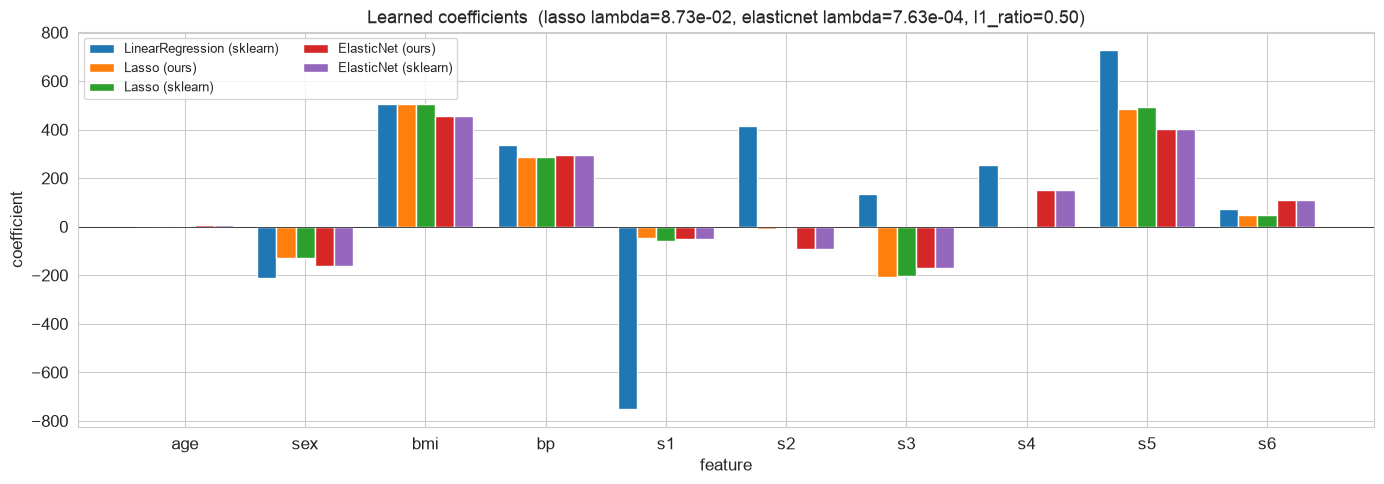

In [130]:
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(feature_names))
width = 0.16
for i, (name, m) in enumerate(candidates.items()):
    ax.bar(x + (i - 2) * width, get_coef(m), width, label=name)
ax.axhline(0, color="k", linewidth=0.5)
ax.set_xticks(x, feature_names)
ax.set_xlabel("feature")
ax.set_ylabel("coefficient")
ax.set_title(f"Learned coefficients  "
             f"(lasso lambda={lam_lasso:.2e}, elasticnet lambda={lam_en:.2e}, l1_ratio={r_en:.2f})")
ax.legend(fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "coefficient_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.** LinearRegression preserves all coefficients and achieves the lowest train MSE but the highest
test MSE. Lasso at the CV-selected `lambda` selects only a subset of features within the correlated groups flagged in the EDA (`s1`/`s2` at 0.90, `s3`/`s4` at -0.74), as expected with Lasso's tendency to keep only one feature from a correlated pair. ElasticNet shrinks correlated features together instead of dropping one, so its coefficient vector is denser than Lasso's but
has smaller magnitudes. Our implementations reasonably match sklearn's in both test MSE and coefficient values. All regularized models land within a few percent of OLS on test MSE on this split; the value of Lasso and ElasticNet for this dataset is interpretability and sparsity.

### 2(b) Classification: Digits

In [131]:
# same split/scaling idea as regression, plus one-hot labels for the MLP
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_dig, y_dig, test_size=0.3, random_state=RANDOM_STATE)
scaler_dig = StandardScaler().fit(Xd_train)
Xd_train_s, Xd_test_s = scaler_dig.transform(Xd_train), scaler_dig.transform(Xd_test)
Yd_train_oh = OneHotEncoder(sparse_output=False).fit_transform(yd_train.reshape(-1, 1))

# returns (mean val acc, mean train acc) over 5 folds
def cv_accuracy(make_model, X, y, Y_oh=None, epochs=None):
    va, tr_acc = [], []
    for tr, te in kf.split(X):
        mdl = make_model()
        mdl.fit(X[tr], y[tr]) if Y_oh is None else mdl.fit(X[tr], Y_oh[tr], epochs)
        va.append(accuracy_score(y[te], mdl.predict(X[te])))
        tr_acc.append(accuracy_score(y[tr], mdl.predict(X[tr])))
    return np.mean(va), np.mean(tr_acc)

#### (a) Multiclass SVM (one-vs-rest)

In [132]:
class MulticlassSVM():

    def __init__(self, learning_rate, lambda_param, n_iters):
        self.learning_rate = learning_rate
        self.lambda_param = lambda_param
        self.n_iters = n_iters
        self.W, self.b = None, None   # one weight column and bias per class
        self.losses = None            # objective J at each iteration, one row per class

    def fit(self, X, y):
        m, n = X.shape
        self.classes = np.unique(y)
        self.W, self.b = np.zeros((n, len(self.classes))), np.zeros(len(self.classes))
        self.losses = np.zeros((len(self.classes), self.n_iters))
        for k, c in enumerate(self.classes):
            y_bin = np.where(y == c, 1.0, -1.0)   # one-vs-rest labels: +1 for class c, -1 for the rest
            w, b = np.zeros(n), 0.0
            for t in range(self.n_iters):
                margins = y_bin * (X @ w + b)
                S = margins < 1                    # margin violators: the only points with a hinge gradient
                self.losses[k, t] = self.lambda_param * w @ w + np.maximum(0, 1 - margins).mean()
                grad_w = 2 * self.lambda_param * w - X[S].T @ y_bin[S] / m
                grad_b = -y_bin[S].sum() / m
                w -= self.learning_rate * grad_w
                b -= self.learning_rate * grad_b
            self.W[:, k], self.b[k] = w, b
        return self

    def predict(self, X):
        # score of every class, then pick the class with the highest score
        return self.classes[np.argmax(X @ self.W + self.b, axis=1)]


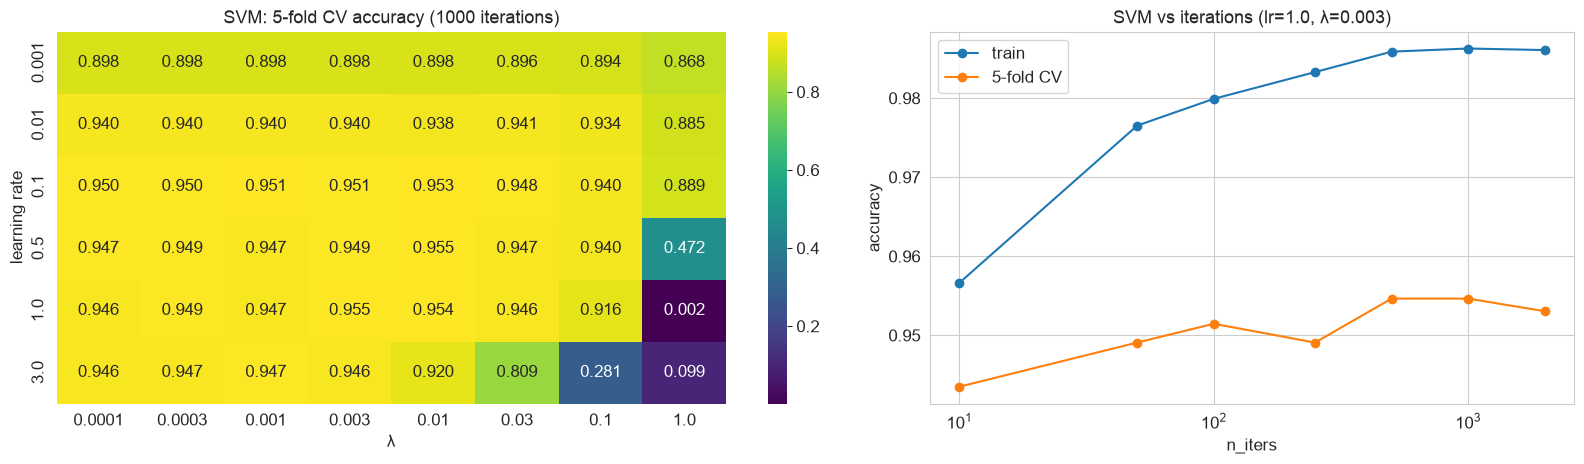

Best: lr = 1.0, λ = 0.003, n_iters = 500  |  CV acc = 0.9547, train acc = 0.9825, test acc = 0.9667


In [133]:
# grid search over lr and lambda first
svm_lrs = [0.001, 0.01, 0.1, 0.5, 1.0, 3.0]
svm_lams = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 1.0]
with np.errstate(over="ignore", invalid="ignore"):
    svm_cv = pd.DataFrame([[cv_accuracy(lambda: MulticlassSVM(lr, lam, 1000), Xd_train_s, yd_train)[0]
                            for lam in svm_lams] for lr in svm_lrs], index=svm_lrs, columns=svm_lams)
svm_lr, svm_lam = svm_cv.stack().idxmax()

# then check how many iterations we actually need
iters_grid = [10, 50, 100, 250, 500, 1000, 2000]
svm_iter = np.array([cv_accuracy(lambda: MulticlassSVM(svm_lr, svm_lam, it), Xd_train_s, yd_train)
                     for it in iters_grid])
svm_n_iters = iters_grid[svm_iter[:, 0].argmax()]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(svm_cv, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set(xlabel="λ", ylabel="learning rate", title="SVM: 5-fold CV accuracy (1000 iterations)")
axes[1].plot(iters_grid, svm_iter[:, 1], marker="o", label="train")
axes[1].plot(iters_grid, svm_iter[:, 0], marker="o", label="5-fold CV")
axes[1].set(xscale="log", xlabel="n_iters", ylabel="accuracy", title=f"SVM vs iterations (lr={svm_lr}, λ={svm_lam})")
axes[1].legend()
plt.tight_layout(); plt.show()

# final model with the best settings
svm = MulticlassSVM(svm_lr, svm_lam, svm_n_iters).fit(Xd_train_s, yd_train)
print(f"Best: lr = {svm_lr}, λ = {svm_lam}, n_iters = {svm_n_iters}  |  CV acc = {svm_iter[:, 0].max():.4f}, "
      f"train acc = {accuracy_score(yd_train, svm.predict(Xd_train_s)):.4f}, "
      f"test acc = {accuracy_score(yd_test, svm.predict(Xd_test_s)):.4f}")

Best: η = 1, λ = 0.003, 500 iterations → **test accuracy 96.7%**.

#### SVM training loss

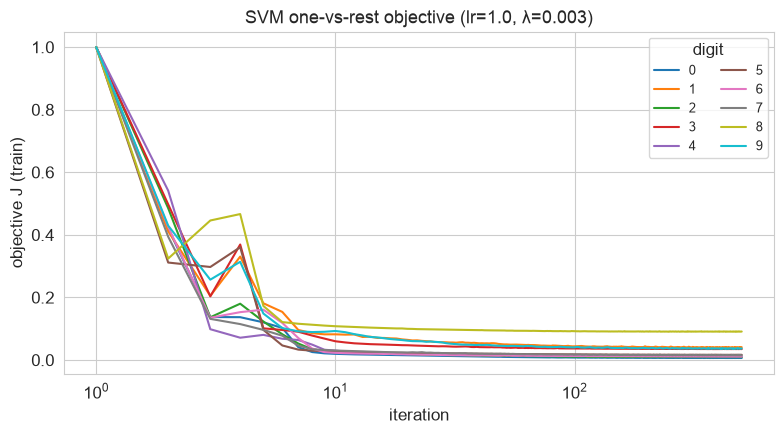

Final J per class: [0.0066 0.041  0.0094 0.035  0.0115 0.0167 0.0114 0.0151 0.0911 0.0371]


In [134]:
# one loss curve per one-vs-rest classifier
plt.figure(figsize=(8, 4.5))
for k in range(len(svm.classes)):
    plt.plot(np.arange(1, svm_n_iters + 1), svm.losses[k], label=str(svm.classes[k]))
plt.xscale("log")
plt.xlabel("iteration"); plt.ylabel("objective J (train)")
plt.title(f"SVM one-vs-rest objective (lr={svm_lr}, λ={svm_lam})")
plt.legend(title="digit", ncol=2, fontsize=9)
plt.tight_layout(); plt.show()
print("Final J per class:", np.round(svm.losses[:, -1], 4))

The loss has converged by ~100 iterations. Digit 8 is the hardest class to separate.

#### SVM decision boundaries (one-vs-rest scores, test set)

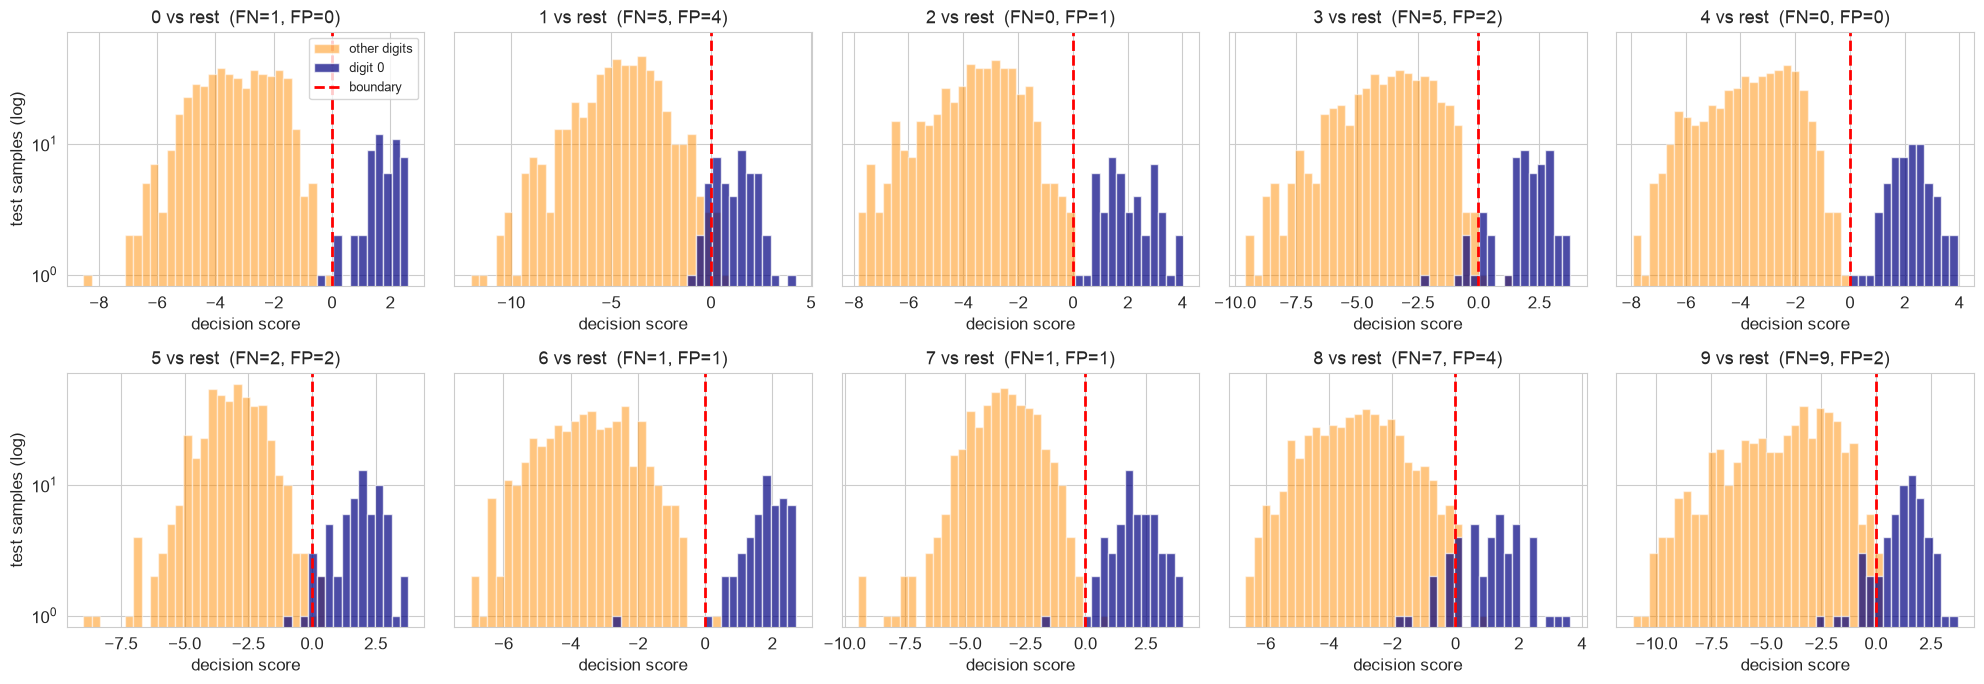

In [135]:
# raw scores for each class on the test set
test_scores = Xd_test_s @ svm.W + svm.b

fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=True)
for k, ax in enumerate(axes.flat):
    s = test_scores[:, k]
    bins = np.linspace(s.min(), s.max(), 40)
    ax.hist(s[yd_test != k], bins=bins, alpha=0.5, color="darkorange", label="other digits")
    ax.hist(s[yd_test == k], bins=bins, alpha=0.7, color="navy", label=f"digit {k}")
    ax.axvline(0, color="red", ls="--", lw=2, label="boundary")
    # count misses (FN) and false alarms (FP) for this binary classifier
    fn, fp = int(((s < 0) & (yd_test == k)).sum()), int(((s >= 0) & (yd_test != k)).sum())
    ax.set(title=f"{k} vs rest  (FN={fn}, FP={fp})", xlabel="decision score")
    ax.set_yscale("log")
axes[0, 0].set_ylabel("test samples (log)"); axes[1, 0].set_ylabel("test samples (log)")
axes[0, 0].legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

Digits 0, 2, 4, 6 and 7 are cleanly separated, while 1, 3, 8 and 9 overlap the boundary the most.

#### SVM decision boundaries (2-D PCA projection)

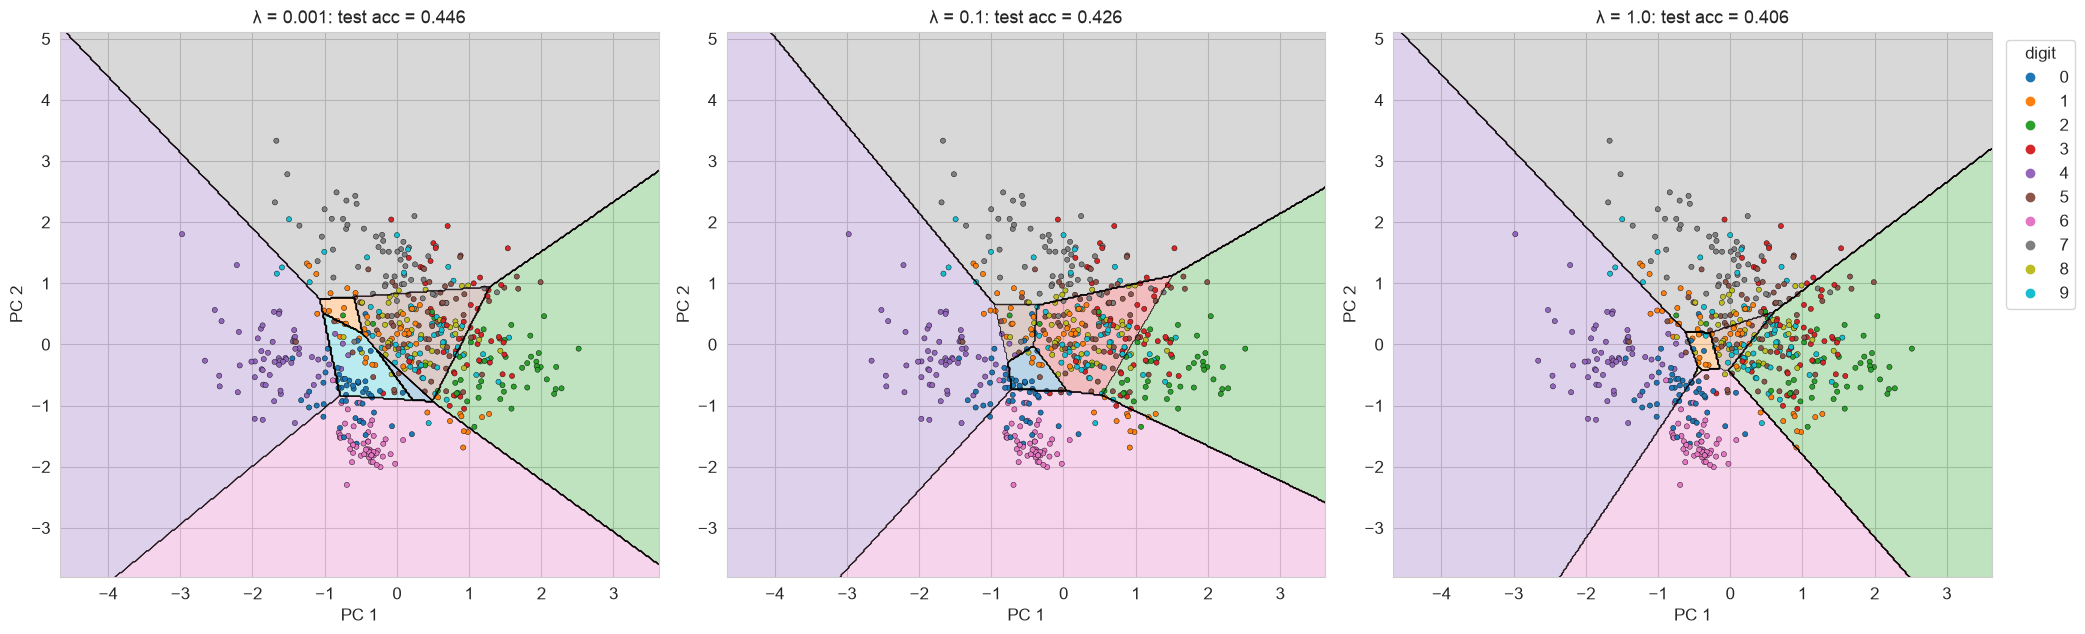

Variance explained by 2 PCs: 0.218


In [136]:
# can't plot 64-D, so project to 2 PCs and retrain the SVM there just to visualise
pca = PCA(n_components=2, whiten=True, random_state=RANDOM_STATE).fit(Xd_train_s)
Z_train, Z_test = pca.transform(Xd_train_s), pca.transform(Xd_test_s)
# grid of points to colour the decision regions
xx, yy = np.meshgrid(np.linspace(Z_train[:, 0].min() - 1, Z_train[:, 0].max() + 1, 400),
                     np.linspace(Z_train[:, 1].min() - 1, Z_train[:, 1].max() + 1, 400))
cmap = plt.get_cmap("tab10")

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, lam in zip(axes, [0.001, 0.1, 1.0]):
    svm2d = MulticlassSVM(0.1, lam, 1000).fit(Z_train, yd_train)
    regions = svm2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, regions, levels=np.arange(-0.5, 10), cmap=cmap, alpha=0.3)
    ax.contour(xx, yy, regions, levels=np.arange(-0.5, 10), colors="k", linewidths=0.5)
    ax.scatter(Z_test[:, 0], Z_test[:, 1], c=yd_test, cmap=cmap, vmin=-0.5, vmax=9.5, s=14, edgecolor="k", lw=0.3)
    ax.set(xlabel="PC 1", ylabel="PC 2",
           title=f"λ = {lam}: test acc = {accuracy_score(yd_test, svm2d.predict(Z_test)):.3f}")
handles = [plt.Line2D([], [], marker="o", ls="", color=cmap(d), label=str(d)) for d in range(10)]
axes[2].legend(handles=handles, title="digit", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
print(f"Variance explained by 2 PCs: {pca.explained_variance_ratio_.sum():.3f}")

The boundaries are linear. 2 PCs keep only 22% of the variance, so accuracy is ≈ 41–45%.

#### (b) Multilayer Perceptron (MLP)

In [137]:
class MLP():

    def __init__(self, input_size, hidden_size, output_size, lr, random_state=RANDOM_STATE):
        rng = np.random.default_rng(random_state)   # seeded weight init -> reproducible runs
        self.lr = lr
        self.W1 = rng.normal(0, np.sqrt(2 / input_size), (input_size, hidden_size))
        self.b1 = np.zeros(hidden_size)
        self.W2 = rng.normal(0, np.sqrt(2 / hidden_size), (hidden_size, output_size))
        self.b2 = np.zeros(output_size)

    def relu(self, Z):
        return np.maximum(0, Z)

    def relu_derivative(self, Z):
        return (Z > 0).astype(float)

    def softmax(self, Z):
        expZ = np.exp(Z - Z.max(axis=1, keepdims=True))   # shift for numerical stability
        return expZ / expZ.sum(axis=1, keepdims=True)

    def forward(self, X):
        Z1 = X @ self.W1 + self.b1
        A1 = self.relu(Z1)
        return Z1, A1, self.softmax(A1 @ self.W2 + self.b2)

    def fit(self, X, y, epochs):
        # y is the one-hot encoded label matrix (m x 10)
        m = X.shape[0]
        self.losses = []
        for _ in range(epochs):
            Z1, A1, Y_hat = self.forward(X)                                 # forward pass
            self.losses.append(-np.sum(y * np.log(Y_hat + 1e-12)) / m)      # cross-entropy loss L
            dZ2 = (Y_hat - y) / m                                            # dL/d(output logits)
            dZ1 = (dZ2 @ self.W2.T) * self.relu_derivative(Z1)               # backpropagate through ReLU
            self.W2 -= self.lr * A1.T @ dZ2                                  # gradient descent updates
            self.b2 -= self.lr * dZ2.sum(axis=0)
            self.W1 -= self.lr * X.T @ dZ1
            self.b1 -= self.lr * dZ1.sum(axis=0)
        return self

    def predict(self, X):
        return np.argmax(self.forward(X)[2], axis=1)

#### MLP tuning (5-fold CV)

In [ ]:
# grid search over hidden size and lr (1000 epochs each)
hidden_grid, mlp_lrs = [8, 16, 32, 64, 128, 256, 512], [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]
mlp_cv = pd.DataFrame([[cv_accuracy(lambda: MLP(64, h, 10, lr), Xd_train_s, yd_train, Yd_train_oh, 1000)[0]
                        for lr in mlp_lrs] for h in hidden_grid], index=hidden_grid, columns=mlp_lrs)
mlp_h, mlp_lr = mlp_cv.stack().idxmax()

# then tune number of epochs with the best combo
epoch_grid = [10, 50, 100, 250, 500, 1000, 2000, 4000, 8000]
mlp_ep = np.array([cv_accuracy(lambda: MLP(64, mlp_h, 10, mlp_lr), Xd_train_s, yd_train, Yd_train_oh, ep)
                   for ep in epoch_grid])
mlp_epochs = epoch_grid[mlp_ep[:, 0].argmax()]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(mlp_cv, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set(xlabel="learning rate", ylabel="hidden size", title="MLP: 5-fold CV accuracy (1000 epochs)")
axes[1].plot(epoch_grid, mlp_ep[:, 1], marker="o", label="train")
axes[1].plot(epoch_grid, mlp_ep[:, 0], marker="o", label="5-fold CV")
axes[1].set(xscale="log", xlabel="epochs", ylabel="accuracy", title=f"MLP vs epochs (hidden={mlp_h}, lr={mlp_lr})")
axes[1].legend()
plt.tight_layout(); plt.show()

# final MLP
mlp = MLP(64, mlp_h, 10, mlp_lr).fit(Xd_train_s, Yd_train_oh, mlp_epochs)
print(f"Best: hidden = {mlp_h}, lr = {mlp_lr}, epochs = {mlp_epochs}  |  CV acc = {mlp_ep[:, 0].max():.4f}, "
      f"train acc = {accuracy_score(yd_train, mlp.predict(Xd_train_s)):.4f}, "
      f"test acc = {accuracy_score(yd_test, mlp.predict(Xd_test_s)):.4f}")

Best: 256 hidden units, η = 0.5, 8000 epochs → **test accuracy 98.0%**.

#### MLP training loss

In [ ]:
# training loss of the final MLP (log-log so it's easier to see)
plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(1, mlp_epochs + 1), mlp.losses)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("cross-entropy loss (train)")
plt.title(f"MLP training loss (hidden={mlp_h}, lr={mlp_lr})")
plt.tight_layout(); plt.show()
print(f"Loss at epoch 1000: {mlp.losses[999]:.5f}, 4000: {mlp.losses[3999]:.5f}, {mlp_epochs}: {mlp.losses[-1]:.5f}")

The loss decreases steadily, with no instability.

#### (c) Comparison with `RandomForestClassifier` (tuned with `GridSearchCV`)

In [ ]:
# small grid search for the random forest (sklearn)
rf_param_grid = {"n_estimators": [50, 100, 300], "max_depth": [None, 10, 20],
                 "max_features": ["sqrt", "log2"], "min_samples_leaf": [1, 2]}
rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), rf_param_grid, cv=kf,
                         scoring="accuracy", n_jobs=-1).fit(Xd_train_s, yd_train)
rf = rf_search.best_estimator_
print("Best RF:", rf_search.best_params_)

# put all three classifiers in one table
clf_models = {"Multiclass SVM (ours)": svm, "MLP (ours)": mlp, "RandomForest (sklearn)": rf}
cv_best = [svm_iter[:, 0].max(), mlp_ep[:, 0].max(), rf_search.best_score_]
print(pd.DataFrame({n: {"CV acc": cv, "train acc": accuracy_score(yd_train, m.predict(Xd_train_s)),
                        "test acc": accuracy_score(yd_test, m.predict(Xd_test_s)),
                        "test errors": int((m.predict(Xd_test_s) != yd_test).sum())}
                    for (n, m), cv in zip(clf_models.items(), cv_best)}).T.round(4))

# confusion matrices to see which digits get mixed up
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (name, m) in zip(axes, clf_models.items()):
    sns.heatmap(confusion_matrix(yd_test, m.predict(Xd_test_s)), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(xlabel="predicted", ylabel="true", title=name)
plt.tight_layout(); plt.show()

MLP (98.0%) > RandomForest (97.2%) > SVM (96.7%).

## Task 3: Predicting tomorrow's S&P 500 returns
The models are retrained every year on a rolling window. Validation: 2001–2010. Test: 2011–2013.

### LLM use
We used an LLM to understand Task 3 before writing the code, with the prompt:

> *"Explain Task 3 of this assignment step by step so I understand the expectations. For each equation, explain what it computes and why it is used."*

We also used Claude to check the notebook against the assignment instructions multiple times and to edit a few cells (Sharpe and PnL over 2001–2013 plots, markdown findings and missing requirements check).

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

# all files are indexed by date, one column per permno
ret = pd.read_csv("eq_returns.csv", index_col=0, parse_dates=True)
ind = pd.read_csv("eq_indicator.csv", index_col=0, parse_dates=True)
bull = pd.read_csv("psych_bullish.csv", index_col=0, parse_dates=True)
bear = pd.read_csv("psych_bearish.csv", index_col=0, parse_dates=True)
member = ind == 1

print("Returns:", ret.shape, ret.index.min().date(), "to", ret.index.max().date())
print("Sentiment:", bull.shape, bull.index.min().date(), "to", bull.index.max().date())
print("Members per day: min", member.sum(axis=1).min(), " max", member.sum(axis=1).max())
print("Return values available for non-members:", int((ret.notna() & ~member).sum().sum()))
print("Missing returns for members:", int((ret.isna() & member).sum().sum()))
print("Duplicated permno columns (renamed by pandas):", int(ret.columns.str.contains(r"\.").sum()))

There are ~500 members per day and no missing returns for members. The 21 duplicated permnos are treated as separate series.

### 3(a) Volatility adjustment
EWMA filters with β1 = 0.97, β2 = 0.99 and a 60-day burn-in.

In [ ]:
def ewma_vol(R, b1=0.97, b2=0.99, burn=60):
    R = R.values
    T, N = R.shape
    mu, s2, count = np.zeros(N), np.full(N, np.nan), np.zeros(N)
    sigma = np.full((T, N), np.nan)
    for t in range(T):
        ok = ~np.isnan(R[t])
        s2[ok & np.isnan(s2)] = 0.02 ** 2              # starting guess for a new stock
        mu[ok] = (1 - b2) * R[t, ok] + b2 * mu[ok]     # Eq. 3
        a = R[t, ok] - mu[ok]
        s2[ok] = (1 - b1) * a ** 2 + b1 * s2[ok]       # Eq. 2
        count[ok] += 1
        sigma[t] = np.where(count >= burn, np.sqrt(s2), np.nan)
    return sigma

sigma = pd.DataFrame(ewma_vol(ret), index=ret.index, columns=ret.columns)
radj = ret / sigma.shift(1)    # use yesterday's volatility -> no look-ahead

print("Std of raw returns (members):", round(ret[member].stack().std(), 4))
print("Std of vol-adjusted returns (members):", round(radj[member].stack().std(), 3))

In [ ]:
# example: AAPL (permno 14593)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(ret["14593"], lw=0.5); axes[0].set_title("AAPL raw return")
axes[0].set(xlabel="date", ylabel="daily return")
axes[1].plot(radj["14593"], lw=0.5); axes[1].set_title("AAPL vol-adjusted return")
axes[1].set(xlabel="date", ylabel="return / σ (previous day)")
# average volatility across members over time
axes[2].plot(sigma[member].mean(axis=1), lw=0.8); axes[2].set_title("Mean estimated volatility (members)")
axes[2].set(xlabel="date", ylabel="mean daily σ")
plt.tight_layout(); plt.show()

After adjustment, the returns are roughly stationary with std ≈ 1.

### 3(b) Features and target
Features for day t (`rev1`, `rev5`, `mom20`, `mom60`, `mom250`, `vol`) use only returns up to day t. The target is the demeaned volatility-adjusted return on day t+1.

In [ ]:
rc = radj.clip(-5, 5)   # clip extreme values so a few outliers don't dominate training
valid = member & radj.notna()

def cs_zscore(df):
    # standardise across stocks on each day (members only)
    df = df.where(valid)
    z = df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1), axis=0)
    return z.clip(-3, 3)

raw_feats = {"rev1": rc,
             "rev5": rc.rolling(5, min_periods=3).mean(),
             "mom20": rc.rolling(20, min_periods=10).mean(),
             "mom60": rc.rolling(60, min_periods=30).mean(),
             "mom250": rc.shift(20).rolling(230, min_periods=120).mean(),
             "vol": np.log(sigma)}
FEATS = list(raw_feats)

target = rc.shift(-1).where(valid)                   # tomorrow's return, for stocks that are members today
target = target.sub(target.mean(axis=1), axis=0)

# long format: one row per (date, stock)
panel = pd.DataFrame({k: cs_zscore(v).stack() for k, v in raw_feats.items()})
panel["y"] = target.stack()
panel = panel.dropna(subset=FEATS)
print("Panel shape:", panel.shape)
panel.head()

In [ ]:
# daily rank correlation (Spearman) of each feature with tomorrow's return
d = panel.dropna()
ic = pd.DataFrame({f: d.groupby(level=0).apply(lambda g: g[f].corr(g["y"], method="spearman")) for f in FEATS})
print(pd.DataFrame({"1981-2000": ic[:"2000"].mean(), "2001-2010 (val)": ic["2001":"2010"].mean()}).round(4))

(ic[:"2010"].cumsum()).plot(figsize=(10, 4.5), title="Cumulative daily rank correlation of each feature (up to 2010)")
plt.ylabel("cumulative rank corr"); plt.show()

All signals are weak (|mean rank corr| ≈ 0.01–0.03). `rev1` changes sign around 1992, which is why we retrain on a rolling window.

### 3(c) Evaluation metrics
Predictions are demeaned each day and scaled so that Σ|r̂| = 1. Sharpe ratio: Eq. 4. PnL: Eq. 6. Holding period: Eq. 7.

In [ ]:
real_next = radj.shift(-1).where(member)      # actual (unclipped) vol-adjusted return of tomorrow
market_next = ret.shift(-1)[member].mean(axis=1)   # equal-weighted long-only portfolio

def to_weights(p):
    p = p.sub(p.mean(axis=1), axis=0)           # market neutral
    return p.div(p.abs().sum(axis=1), axis=0)   # unit gross exposure

def evaluate(w, start=None, end=None):
    w = w.loc[start:end]
    rn = real_next.reindex_like(w)
    pnl = (w * rn).sum(axis=1, min_count=1).dropna()
    rank_ic = w.corrwith(rn, axis=1, method="spearman").dropna()
    hold = (w.abs().mean() / w.diff().abs().mean()).replace(np.inf, np.nan).mean()   # Eq. 7
    stats = {"Sharpe": pnl.mean() / pnl.std() * np.sqrt(252),
             "mean rank corr": rank_ic.mean(),
             "holding period": hold,
             "market corr": pnl.corr(market_next.reindex(pnl.index)),
             "min stocks/day": int(w.notna().sum(axis=1).min())}
    return stats, pnl, rank_ic

### 3(d) Rolling training and tuning (validation 2001–2010)

In [ ]:
def rolling_predict(make_model, test_years, window=10, n_sub=None, data=panel, feats=FEATS):
    yrs = data.index.get_level_values(0).year
    out, models = [], {}
    for Y in test_years:
        tr = data[(yrs >= Y - window) & (yrs < Y)].dropna(subset=["y"])
        tr = tr[tr.index.get_level_values(0) < tr.index.get_level_values(0).max()]   # 1-day gap
        if n_sub and len(tr) > n_sub:            # subsample to keep RF / MLP fast
            tr = tr.sample(n_sub, random_state=42)
        te = data[yrs == Y]
        models[Y] = make_model().fit(tr[feats].values, tr["y"].values)
        out.append(pd.Series(models[Y].predict(te[feats].values), index=te.index))
    return to_weights(pd.concat(out).unstack()), models

VAL, TEST = range(2001, 2011), range(2011, 2014)

In [ ]:
# Lasso: penalty alpha and training window length
lasso_res = {}
for window in [5, 10, 20]:
    for alpha in [1e-4, 1e-3, 3e-3, 1e-2]:
        w, _ = rolling_predict(lambda: Lasso(alpha=alpha), VAL, window=window)
        lasso_res[(window, alpha)] = evaluate(w)[0]
lasso_res = pd.DataFrame(lasso_res).T.rename_axis(["window", "alpha"])
lasso_res.round(3)

In [ ]:
best_window, best_alpha = lasso_res["Sharpe"].idxmax()
w_val_lasso, lasso_models = rolling_predict(lambda: Lasso(alpha=best_alpha), VAL, window=best_window)
print("Best Lasso: window =", best_window, " alpha =", best_alpha)
# coefficients learned each year
pd.DataFrame({Y: m.coef_ for Y, m in lasso_models.items()}, index=FEATS).T.round(4)

Best Lasso: 10-year window, α = 1e-4. Larger α removes weak features and lowers the Sharpe ratio. The row with window = 5 and α = 0.01 is degenerate: in 2009 and 2010 Lasso sets all six coefficients to exactly 0, so every stock gets the same prediction, the demeaned prediction is 0 for all stocks and the weights become NaN (0/0). That is why it shows 0 stocks/day and a meaningless holding period (862 days); this setting is excluded.

In [ ]:
# RandomForest and MLP: small grids, trained on 200k sampled rows from the same 10-year window
nonlin_res, nonlin_w = {}, {}
rf_grid = [(4, 500), (8, 200), (12, 100)]      # (max_depth, min_samples_leaf)
for depth, leaf in rf_grid:
    w, _ = rolling_predict(lambda: RandomForestRegressor(n_estimators=50, max_depth=depth, min_samples_leaf=leaf,
                                                         max_features=0.5, n_jobs=-1, random_state=42),
                           VAL, window=best_window, n_sub=200_000)
    nonlin_res[f"RF depth={depth}, leaf={leaf}"], nonlin_w[("RF", depth)] = evaluate(w)[0], w

for hidden in [(8,), (32,), (32, 16)]:
    w, _ = rolling_predict(lambda: MLPRegressor(hidden_layer_sizes=hidden, alpha=1e-3, max_iter=30,
                                                early_stopping=True, random_state=42),
                           VAL, window=best_window, n_sub=200_000)
    nonlin_res[f"MLP hidden={hidden}"], nonlin_w[("MLP", hidden)] = evaluate(w)[0], w

nonlin_res = pd.DataFrame(nonlin_res).T
nonlin_res.round(3)

Chosen settings: RandomForest depth 8, leaf 200; MLP hidden = (32,). For the RandomForest we do not take depth 12 even though it has the highest validation Sharpe (2.92 vs 2.68): its holding period drops below 1 day and the deeper trees are more likely to overfit the noise, so we prefer the shallower model. Both beat Lasso on validation Sharpe, but they hold positions for only ~1 day.

### 3(e) Smoothing the predictions
Each stock's prediction is smoothed with a past-only EWMA (half-life h).

In [ ]:
best_mlp = max([k for k in nonlin_w if k[0] == "MLP"], key=lambda k: nonlin_res.loc[f"MLP hidden={k[1]}", "Sharpe"])
val_preds = {"Lasso": w_val_lasso, "RF": nonlin_w[("RF", 8)], "MLP": nonlin_w[best_mlp]}

def smooth(w, halflife):
    if halflife == 0:
        return w
    return to_weights(w.ewm(halflife=halflife, ignore_na=True).mean().where(w.notna()))

smooth_res = {(name, h): evaluate(smooth(w, h))[0] for name, w in val_preds.items() for h in [0, 1, 2, 5, 10, 20]}
smooth_res = pd.DataFrame(smooth_res).T.rename_axis(["model", "half-life"])

plt.figure(figsize=(8, 5))
for name in val_preds:
    r = smooth_res.loc[name]
    plt.plot(r["holding period"], r["Sharpe"], "o-", label=name)
    for h, row in r.iterrows():
        plt.annotate(str(h), (row["holding period"], row["Sharpe"]), fontsize=9)
plt.xscale("log"); plt.xlabel("holding period (days)"); plt.ylabel("Sharpe ratio (2001-2010)")
plt.title("Sharpe vs holding period (labels = half-life)"); plt.legend(); plt.show()
smooth_res[["Sharpe", "holding period", "mean rank corr"]].round(3)

Smoothing lengthens the holding period but lowers the Sharpe ratio. We pick h = 2 (validation holding period ≈ 2.9–3.9 days).

### 3(f) Final test (2011–2013)

In [ ]:
w_test = {"Lasso": rolling_predict(lambda: Lasso(alpha=best_alpha), TEST, window=best_window)[0],
          "RF": rolling_predict(lambda: RandomForestRegressor(n_estimators=50, max_depth=8, min_samples_leaf=200,
                                                              max_features=0.5, n_jobs=-1, random_state=42),
                                TEST, window=best_window, n_sub=200_000)[0],
          "MLP": rolling_predict(lambda: MLPRegressor(hidden_layer_sizes=best_mlp[1], alpha=1e-3, max_iter=30,
                                                      early_stopping=True, random_state=42),
                                 TEST, window=best_window, n_sub=200_000)[0]}

HL = 2
test_res, test_pnl, test_ic = {}, {}, {}
for name, w in w_test.items():
    for h in [0, HL]:
        label = f"{name} (h={h})"
        test_res[label], test_pnl[label], test_ic[label] = evaluate(smooth(w, h))
pd.DataFrame(test_res).T.round(3)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for label in test_pnl:
    ls = "-" if label.endswith("h=0)") else "--"
    axes[0].plot(test_pnl[label].cumsum(), ls, label=label)
    axes[1].plot(test_ic[label].cumsum(), ls, label=label)
axes[0].set_title("Test PnL: cumulative sum of $R_t$"); axes[0].set_ylabel("cumulative PnL")
axes[1].set_title("Test: cumulative daily rank correlation"); axes[1].set_ylabel("cumulative Spearman corr")
axes[0].legend(fontsize=9); plt.tight_layout(); plt.show()

In [ ]:
# Sharpe over sub-periods and over the whole 2001-2013 period (validation models + test models)
windows = {"2001-2005": ("2001", "2005"), "2006-2010": ("2006", "2010"),
           "2011-2013 (test)": ("2011", "2013"), "2001-2013 (all)": ("2001", "2013")}
all_w = {name: pd.concat([val_preds[name], w_test[name]]) for name in val_preds}
display(pd.DataFrame({f"{name} (h={h})": {win: evaluate(smooth(w, h), a, b)[0]["Sharpe"] for win, (a, b) in windows.items()}
                      for name, w in all_w.items() for h in [0, HL]}).T.round(2))

# PnL and rank correlation for the whole period, so we can see if the performance is steady over time
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
yearly = {}
for name, w in all_w.items():
    for h in [0, HL]:
        _, pnl, ic = evaluate(smooth(w, h))
        ls = "-" if h == 0 else "--"
        axes[0].plot(pnl.cumsum(), ls, label=f"{name} (h={h})")
        axes[1].plot(ic.cumsum(), ls, label=f"{name} (h={h})")
        yearly[f"{name} (h={h})"] = pnl.groupby(pnl.index.year).apply(lambda x: x.mean() / x.std() * np.sqrt(252))
for ax in axes:
    ax.axvline(pd.Timestamp("2011-01-01"), color="gray", ls=":")   # test set starts here
axes[0].set_title("PnL 2001-2013: cumulative sum of $R_t$"); axes[0].set_ylabel("cumulative PnL")
axes[1].set_title("Cumulative daily rank correlation, 2001-2013"); axes[1].set_ylabel("cumulative Spearman corr")
axes[0].legend(fontsize=9); plt.tight_layout(); plt.show()

# Sharpe of each year, to check for bad years
pd.DataFrame(yearly).T.round(2)


- All models have a positive test Sharpe ratio. RF is best (SR 4.0, or 2.9 with h = 2). Smoothed Lasso reaches SR ≈ 2.0 with a holding period of ≈ 4.3 days.
- Every year from 2001 to 2013 is positive for every model. The weakest years are 2007–2008.
- Market correlation is ≈ 0.17–0.42, because the low-volatility tilt makes the dollar exposure net long. Transaction costs are not included.

### 3(g) Adding the Psychsignal sentiment signals
Lasso with vs without net sentiment and activity (7-day averages). Trained from 2009-07, tested on 2011–2013.

In [ ]:
# map sentiment to the return columns (first column for duplicated permnos) and to trading days
cols = [c for c in ret.columns if c in bull.columns]
net = (bull - bear).rolling("7D").mean()
activity = (bull + bear).rolling("7D").mean()
sent = {"net_sent": net, "activity": activity}
sent = {k: v.reindex(columns=cols).reindex(ret.index).reindex(columns=ret.columns) for k, v in sent.items()}

print("Stocks with sentiment per day (members):")
print(sent["net_sent"].where(member).notna().sum(axis=1)["2009-07":"2013"].resample("YE").mean().round(0))

panel_s = panel.loc["2009-07":"2013"].copy()
for k, v in sent.items():
    panel_s[k] = cs_zscore(v).stack().reindex(panel_s.index).fillna(0)   # no messages -> neutral
FEATS_S = FEATS + list(sent)

# rank correlation of the sentiment features with tomorrow's return (2009-07 to 2010, training period)
d = panel_s.loc[:"2010"].dropna()
print(pd.Series({f: d.groupby(level=0).apply(lambda g: g[f].corr(g["y"], method="spearman")).mean()
                 for f in sent}).round(4))

In [ ]:
sent_res = {}
for name, feats in [("Lasso, returns only", FEATS), ("Lasso, returns + sentiment", FEATS_S)]:
    w, models = rolling_predict(lambda: Lasso(alpha=best_alpha), TEST, window=3, data=panel_s, feats=feats)  # up to 3 years, starting 2009-07
    for h in [0, HL]:
        sent_res[f"{name} (h={h})"] = evaluate(smooth(w, h))[0]
    if feats == FEATS_S:   # keep the sentiment model's coefficients to inspect them
        sent_coef = pd.DataFrame({Y: m.coef_ for Y, m in models.items()}, index=feats).T
display(pd.DataFrame(sent_res).T.round(3))
sent_coef.round(4)

Sentiment adds only a small, non-significant gain (test SR 1.78 → 1.92 unsmoothed, 1.52 → 1.61 with h = 2).